# Practice Notebook 3 (Week 2): Resampling, Permutation Tests and the Bootstrap

Advanced Statistics Course, Brain Science, Period 2

This notebook lets you practise the two resampling methods of Week 2: the **permutation test** and the **bootstrap**. It combines **paper-and-pencil exercises** (do these by hand first, **do not use Python**) with **Python exercises**.

**How to use this notebook:** every exercise is followed by its solution. For the coding parts, first work in the cell marked `# your answer`, then compare with the solution cell(s) underneath. Try not to scroll ahead.

For the Python exercises you need *numpy*, *pandas*, *scipy* and *matplotlib*.

### Learning Goals
- Carry out an exact permutation test by enumerating all label assignments, and a Monte Carlo approximation.
- Use permutation tests with different test statistics (mean, median, $\chi^2$).
- Compute a bootstrap standard error and percentile confidence interval for a two-group difference and a correlation.
- Recognise typical resampling bugs (wrong replacement, wrong unit of resampling, wrong sample size).
- Explain why a permutation test and a bootstrap CI can disagree on the same data.

## Part 1: Exact Permutation Test

**3.1** In a pilot study, 3 rats received a placebo and 3 rats received a memory-enhancing drug. The number of correct arm choices in a radial maze was:

- Placebo (A): `{4, 6, 9}`
- Drug (B): `{10, 11, 13}`

Test statistic: $\bar{x}_A - \bar{x}_B$. Use a **two-sided** test at $\alpha = 0.05$.

### Tasks (paper and pencil, **do not use Python!**)
a) Compute the observed statistic.

b) How many ways are there to split the 6 pooled values into two groups of 3?

c) How many of these splits give a statistic at least as extreme as the observed one (in absolute value)? *Hint:* the pooled sum is 53, so a split in which group A has sum $s$ gives $\bar{x}_A - \bar{x}_B = (2s - 53)/3$.

d) Compute the exact p-value and decide.

e) What is the **smallest possible two-sided p-value** in a 3 + 3 design? What does that imply?

### Answer 3.1

**a)** $\bar{x}_A = 19/3 = 6.33$, $\bar{x}_B = 34/3 = 11.33$, so the observed difference is $-5$.

**b)** $\binom{6}{3} = 20$ splits.

**c)** $|2s - 53|/3 \ge 5 \iff |2s - 53| \ge 15 \iff s \le 19$ or $s \ge 34$. The smallest possible sum of 3 values is $4 + 6 + 9 = 19$ and the largest is $10 + 11 + 13 = 34$. Each occurs for exactly **one** split (the observed one and its mirror image), so **2** splits.

**d)** $p = 2/20 = 0.10 > 0.05$, so we **fail to reject $H_0$**, even though the groups do not overlap at all.

**e)** The observed split is already the most extreme possible, so $p_{min} = 2/20 = 0.10$ (one-sided: $1/20 = 0.05$, still not $< 0.05$). A 3 + 3 permutation test **can never be significant at $\alpha = .05$**, whatever the data. This is the same situation as the lecture example $A = \{5,7,6\}$, $B = \{8,9,10\}$: "weak evidence against $H_0$".

**3.2** Exact and Monte Carlo permutation tests in Python.

1. Write a function `exact_perm_test(x, y)` that enumerates **all** ways of assigning the pooled values to the groups (`itertools.combinations` of the indices) and returns the observed mean difference and the two-sided p-value. Check it on the rat data from **3.1**.
2. Apply it to EEG frontal alpha power (µV²) in meditators vs. controls (6 each, so $\binom{12}{6} = 924$ splits).
3. Write `mc_perm_test(x, y, n_perm, rng)` that uses random shuffles instead. Run it **20 times each** with `n_perm` = 100, 1,000 and 10,000, and report the mean and standard deviation of the 20 p-values. What do you observe?
4. Check your exact result with `stats.permutation_test`.

In [ ]:
import itertools
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

placebo = np.array([4, 6, 9])
drug = np.array([10, 11, 13])

meditators = np.array([12.1, 14.3, 11.8, 15.2, 13.9, 16.4])
controls = np.array([10.2, 11.5, 9.8, 12.7, 10.9, 13.1])

def exact_perm_test(x, y):
    # your answer
    pass

def mc_perm_test(x, y, n_perm, rng):
    # your answer
    pass

# your answer

### Solution 3.2

Rats:  observed diff = -5.00, exact p = 0.1000
EEG:   observed diff = 2.58, exact p = 0.0216 (924 splits)


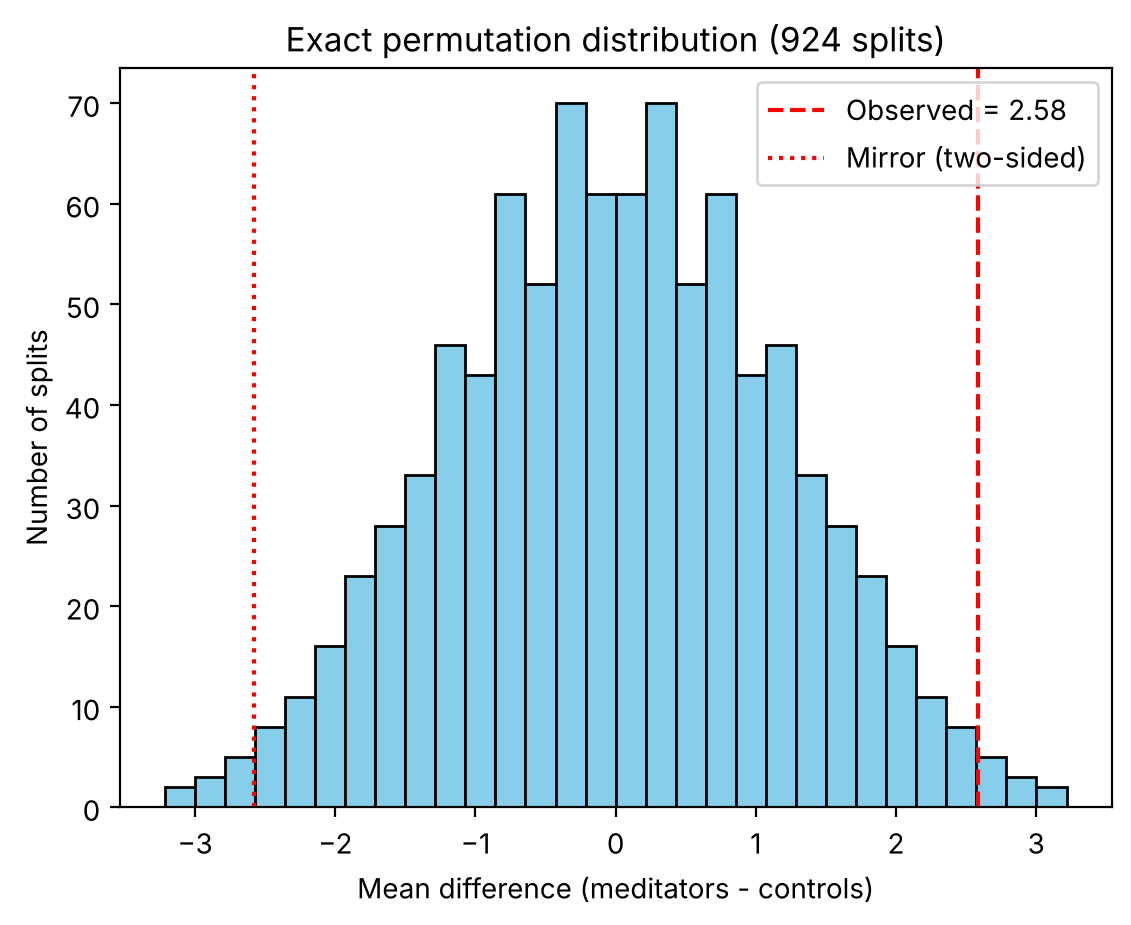

In [2]:
import itertools
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

placebo = np.array([4, 6, 9])
drug = np.array([10, 11, 13])

meditators = np.array([12.1, 14.3, 11.8, 15.2, 13.9, 16.4])
controls = np.array([10.2, 11.5, 9.8, 12.7, 10.9, 13.1])

def exact_perm_test(x, y):
    pooled = np.concatenate([x, y])
    n_x = len(x)
    observed = x.mean() - y.mean()
    diffs = []
    for idx in itertools.combinations(range(len(pooled)), n_x):
        in_x = np.zeros(len(pooled), dtype=bool)
        in_x[list(idx)] = True
        diffs.append(pooled[in_x].mean() - pooled[~in_x].mean())
    diffs = np.array(diffs)
    p = np.mean(np.abs(diffs) >= np.abs(observed) - 1e-12)   # tolerance for floating-point ties
    return observed, p, diffs

obs, p, _ = exact_perm_test(placebo, drug)
print(f"Rats:  observed diff = {obs:.2f}, exact p = {p:.4f}")

obs_eeg, p_eeg, diffs_eeg = exact_perm_test(meditators, controls)
print(f"EEG:   observed diff = {obs_eeg:.2f}, exact p = {p_eeg:.4f} ({len(diffs_eeg)} splits)")

plt.hist(diffs_eeg, bins=30, color="skyblue", edgecolor="black")
plt.axvline(obs_eeg, color="red", linestyle="dashed", label=f"Observed = {obs_eeg:.2f}")
plt.axvline(-obs_eeg, color="red", linestyle="dotted", label="Mirror (two-sided)")
plt.xlabel("Mean difference (meditators - controls)")
plt.ylabel("Number of splits")
plt.title("Exact permutation distribution (924 splits)")
plt.legend()
plt.show()

In [3]:
# 3. Monte Carlo approximation: how stable is the estimated p-value?
def mc_perm_test(x, y, n_perm, rng):
    pooled = np.concatenate([x, y])
    observed = x.mean() - y.mean()
    diffs = np.empty(n_perm)
    for i in range(n_perm):
        shuffled = rng.permutation(pooled)            # sampling WITHOUT replacement
        diffs[i] = shuffled[:len(x)].mean() - shuffled[len(x):].mean()
    return np.mean(np.abs(diffs) >= np.abs(observed) - 1e-12)

rng = np.random.default_rng(42)
rows = []
for n_perm in [100, 1000, 10000]:
    ps = [mc_perm_test(meditators, controls, n_perm, rng) for _ in range(20)]
    rows.append({"n_perm": n_perm, "mean p": np.mean(ps), "SD of p": np.std(ps, ddof=1)})
print(pd.DataFrame(rows).round(4))
print(f"Exact p = {p_eeg:.4f}")

# 4. scipy check (n_resamples=np.inf -> exact enumeration)
res = stats.permutation_test((meditators, controls),
                             lambda a, b: np.mean(a) - np.mean(b),
                             permutation_type="independent",
                             n_resamples=np.inf, alternative="two-sided")
print(f"scipy exact permutation test: p = {res.pvalue:.4f}")

   n_perm  mean p  SD of p
0     100  0.0215   0.0166
1    1000  0.0226   0.0042
2   10000  0.0217   0.0018
Exact p = 0.0216
scipy exact permutation test: p = 0.0216


- Rats: $p = 0.10$, as computed by hand.
- EEG: exact $p \approx 0.022$, so meditators show significantly higher alpha power.
- All three Monte Carlo settings are centred on the exact p-value, but the **spread** shrinks as `n_perm` grows (roughly by a factor $\sqrt{10}$ per tenfold increase). With 100 permutations, the decision at $\alpha = .05$ could flip from run to run. More permutations cost more computation but give a more precise p-value. For small samples, you can simply enumerate everything and get the exact answer.
- *Side note:* many implementations use $(k+1)/(B+1)$ instead of $k/B$ for the Monte Carlo p-value (counting the observed labelling as one of the permutations), so that $p$ can never be exactly 0.

**3.3** A permutation test works with **any** test statistic. During EEG recording, one control participant produced an artefact, so their value is 30.0 instead of 13.1:

- Meditators: `[12.1, 14.3, 11.8, 15.2, 13.9, 16.4]`
- Controls (with artefact): `[10.2, 11.5, 9.8, 12.7, 10.9, 30.0]`

1. Write a general function `perm_test(x, y, stat_func, n_perm, rng)` that takes the statistic as an argument.
2. Run it (10,000 permutations, `rng = np.random.default_rng(3)`) with (a) the difference in **means** and (b) the difference in **medians**.
3. Compare the two p-values and explain the difference.

In [ ]:
controls_artefact = np.array([10.2, 11.5, 9.8, 12.7, 10.9, 30.0])

def perm_test(x, y, stat_func, n_perm, rng):
    # your answer
    pass

# your answer

### Solution 3.3

In [5]:
controls_artefact = np.array([10.2, 11.5, 9.8, 12.7, 10.9, 30.0])

def perm_test(x, y, stat_func, n_perm, rng):
    pooled = np.concatenate([x, y])
    observed = stat_func(x, y)
    perm_stats = np.empty(n_perm)
    for i in range(n_perm):
        shuffled = rng.permutation(pooled)
        perm_stats[i] = stat_func(shuffled[:len(x)], shuffled[len(x):])
    return observed, np.mean(np.abs(perm_stats) >= np.abs(observed) - 1e-12)

rng = np.random.default_rng(3)
mean_diff = lambda a, b: np.mean(a) - np.mean(b)
median_diff = lambda a, b: np.median(a) - np.median(b)

for name, f in [("mean", mean_diff), ("median", median_diff)]:
    obs, p = perm_test(meditators, controls_artefact, f, 10000, rng)
    print(f"Difference in {name}s: observed = {obs:.2f}, p = {p:.4f}")

Difference in means: observed = -0.23, p = 0.9945


Difference in medians: observed = 2.90, p = 0.0930


The single artefact pulls the control **mean** up so far that the mean difference almost vanishes ($-0.23$, $p \approx 1$). The **median** is barely affected by one extreme value, so the median difference (2.9) still reflects the group difference ($p \approx .09$: far from 1, but not significant with only 6 per group). The permutation framework does not care which statistic you use: you simply recompute *your* statistic for every shuffle. Choose the statistic **before** looking at the data (choosing whichever gives the smallest p afterwards is p-hacking). The better fix here is to deal with the artefact itself.

**3.4** Permutation tests also work for **categorical** data. Take the sleep-deprivation table (n = 24):

|                 | False memory | No false memory |
|-----------------|--------------|-----------------|
| Sleep-deprived  | 10           | 2               |
| Rested          | 5            | 7               |

1. Re-create the raw data: one array `group` (1 = sleep-deprived, 0 = rested) and one array `outcome` (1 = false memory, 0 = none), with one entry per participant.
2. Use the $\chi^2$ statistic (no continuity correction) as the test statistic. Shuffle `outcome` 10,000 times (`rng = np.random.default_rng(5)`), rebuild the table each time, and compute the permutation p-value.
3. Compare with the asymptotic $\chi^2$ p-value and with Fisher's exact test (two-sided).

In [ ]:
def chi2_stat(group, outcome):
    table = pd.crosstab(group, outcome).values
    return stats.chi2_contingency(table, correction=False)[0]

# your answer

### Solution 3.4

In [7]:
def chi2_stat(group, outcome):
    table = pd.crosstab(group, outcome).values
    return stats.chi2_contingency(table, correction=False)[0]

# 1. Raw data: 12 sleep-deprived (10 false memories), 12 rested (5 false memories)
group = np.array([1] * 12 + [0] * 12)
outcome = np.array([1] * 10 + [0] * 2 + [1] * 5 + [0] * 7)

# 2. Permutation distribution of chi-square
rng = np.random.default_rng(5)
observed = chi2_stat(group, outcome)
perm = np.array([chi2_stat(group, rng.permutation(outcome)) for _ in range(10000)])
p_perm = np.mean(perm >= observed - 1e-12)     # chi2 is already "two-sided": large = extreme

# 3. Comparison
table = np.array([[10, 2], [5, 7]])
p_asym = stats.chi2_contingency(table, correction=False)[1]
p_fisher = stats.fisher_exact(table)[1]
print(f"Observed chi2 = {observed:.2f}")
print(f"Permutation p   = {p_perm:.4f}")
print(f"Asymptotic p    = {p_asym:.4f}")
print(f"Fisher exact p  = {p_fisher:.4f}")

Observed chi2 = 4.44
Permutation p   = 0.0876
Asymptotic p    = 0.0350
Fisher exact p  = 0.0894


Shuffling the outcome labels keeps both margins fixed (12/12 participants per group, 15/9 outcomes), which is exactly the null distribution that Fisher's test computes analytically. That is why the **permutation p-value is practically identical to Fisher's exact p-value** (≈ .09), while the asymptotic $\chi^2$ p-value (≈ .035) is too small for this sparse table. For $\chi^2$ only large values are extreme, so we count one tail.

## Part 2: Bootstrap

**3.5** (paper and pencil) The original sample is `{3, 5, 8, 10}`.

a) Which of the following could be a **bootstrap sample**? Justify.
   1. `{3, 3, 8, 10}`
   2. `{3, 5, 8}`
   3. `{5, 8, 10, 12}`
   4. `{10, 10, 10, 10}`
   5. `{10, 8, 5, 3}`

b) For each valid bootstrap sample, compute its mean.

c) Which of the five could be the first group of a **permutation** of the pooled data `{3, 5, 8, 10}` ∪ `{1, 2, 4, 6}` (group sizes 4 and 4)?

### Answer 3.5

**a)**
1. ✓ Valid: drawn with replacement (3 appears twice), same size.
2. ✗ Wrong size: a bootstrap sample has the **same size** as the original (4).
3. ✗ 12 is not in the original sample. The bootstrap only reuses observed values.
4. ✓ Valid (unlikely, $(1/4)^4 = 0.4\%$, but possible with replacement).
5. ✓ Valid: same values as the original. Order does not matter, and drawing each value once is possible.

**b)** Means: (1) $24/4 = 6.0$, (4) $10.0$, (5) $26/4 = 6.5$ (the original mean).

**c)** In a permutation each pooled observation appears **exactly once** (sampling without replacement). Only (5) works. (1) and (4) repeat values, (2) has the wrong size, and (3) contains a value that is not in the pooled data.

**3.6** Bootstrap for a two-group difference, using the EEG data from **3.2** (without the artefact).

1. Draw $B = 10{,}000$ bootstrap resamples, resampling **each group separately** with replacement. Compute the mean difference each time. Use `rng = np.random.default_rng(10)`.
2. Compute the bootstrap SE with the formula $SE = \sqrt{\frac{1}{B-1}\sum_b (t^*_b - \bar{t}^*)^2}$ (and check that it equals `np.std(..., ddof=1)`).
3. Compute the 95 % percentile CI. Does it exclude 0? What does its sign tell you?
4. Compare with `stats.bootstrap` using `method="percentile"`.
5. Plot the bootstrap distribution with the CI limits.

In [ ]:
B = 10000
rng = np.random.default_rng(10)

# your answer

### Solution 3.6

In [9]:
B = 10000
rng = np.random.default_rng(10)

# 1. Resample each group with replacement (same size as the original group)
boot = np.empty(B)
for b in range(B):
    m_star = rng.choice(meditators, size=len(meditators), replace=True)
    c_star = rng.choice(controls, size=len(controls), replace=True)
    boot[b] = m_star.mean() - c_star.mean()

# 2. Bootstrap SE
se_formula = np.sqrt(np.sum((boot - boot.mean()) ** 2) / (B - 1))
print(f"Observed difference = {meditators.mean() - controls.mean():.2f}")
print(f"Bootstrap SE (formula) = {se_formula:.3f}, np.std(ddof=1) = {np.std(boot, ddof=1):.3f}")

# 3. Percentile CI
lower, upper = np.percentile(boot, [2.5, 97.5])
print(f"95% percentile CI = [{lower:.2f}, {upper:.2f}]")

# 4. scipy (resamples each sample independently)
res = stats.bootstrap((meditators, controls), lambda a, b: np.mean(a) - np.mean(b),
                      n_resamples=B, method="percentile", random_state=10)
print(f"scipy 95% CI      = [{res.confidence_interval.low:.2f}, {res.confidence_interval.high:.2f}]")

Observed difference = 2.58
Bootstrap SE (formula) = 0.834, np.std(ddof=1) = 0.834
95% percentile CI = [0.95, 4.20]
scipy 95% CI      = [0.93, 4.18]


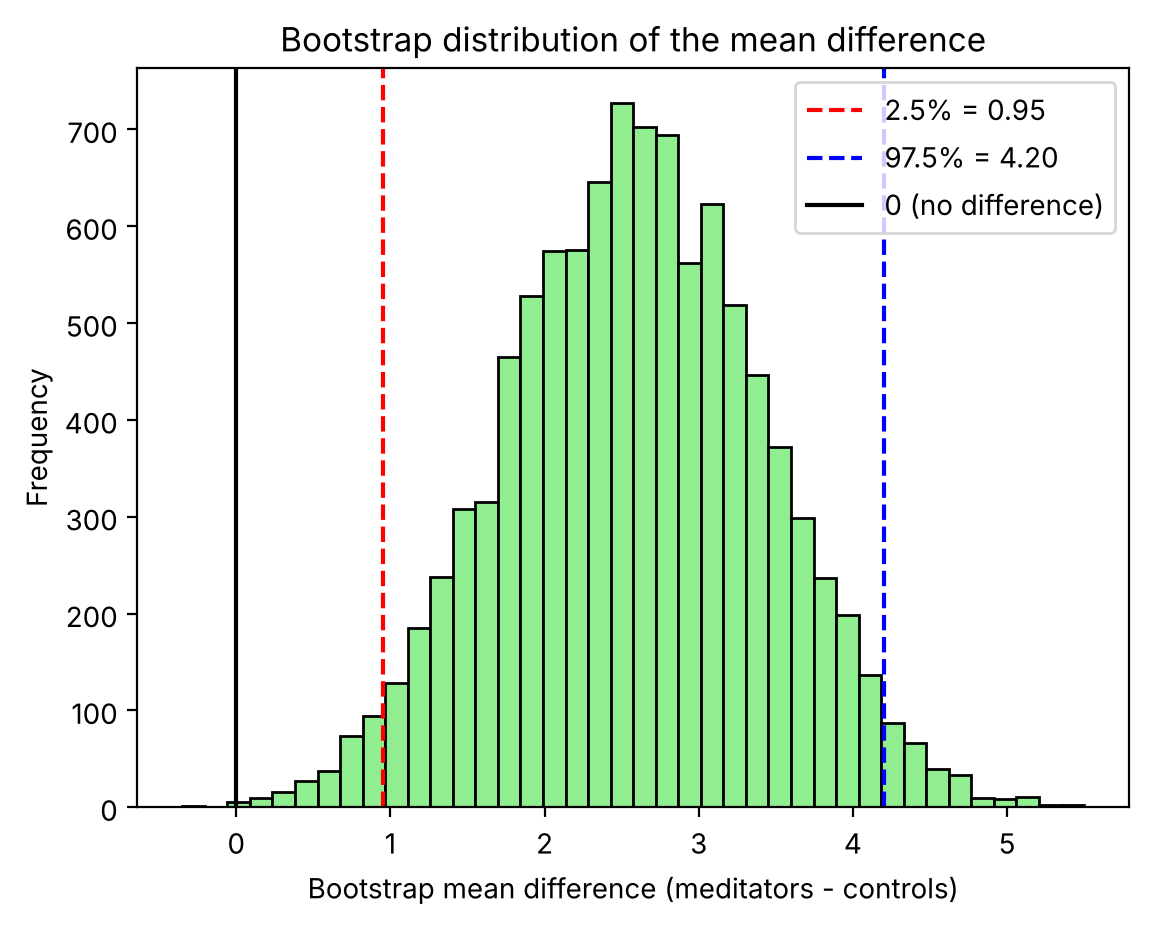

In [10]:
# 5. Plot
plt.hist(boot, bins=40, color="lightgreen", edgecolor="black")
plt.axvline(lower, color="red", linestyle="dashed", label=f"2.5% = {lower:.2f}")
plt.axvline(upper, color="blue", linestyle="dashed", label=f"97.5% = {upper:.2f}")
plt.axvline(0, color="black", label="0 (no difference)")
plt.xlabel("Bootstrap mean difference (meditators - controls)")
plt.ylabel("Frequency")
plt.title("Bootstrap distribution of the mean difference")
plt.legend()
plt.show()

The 95 % CI lies entirely **above 0**, which indicates a significant difference. The positive sign shows that meditators have *higher* alpha power. This agrees with the permutation test in **3.2** ($p \approx .02$). Unlike the p-value, the CI also shows **how large** the difference plausibly is (roughly 1–4 µV²).

**3.7** Bootstrap CI for a **correlation**. Hippocampal volume (cm³) and a delayed-recall score were measured in 15 older adults.

1. Compute Pearson's $r$.
2. Bootstrap a 95 % percentile CI for $r$ ($B = 5{,}000$, `rng = np.random.default_rng(11)`). Think carefully: **what** is the unit you resample?
3. A colleague resamples `volume` and `recall` **independently** of each other. Run this version too and compare the two bootstrap distributions. Why is the colleague's version wrong?

In [ ]:
volume = np.array([3.19, 3.62, 3.76, 3.76, 4.04, 3.27, 3.59, 3.27, 2.90, 3.15, 3.45, 3.08, 3.33, 3.79, 3.60])
recall = np.array([20, 25, 24, 14, 36, 9, 24, 17, 13, 18, 19, 21, 11, 31, 13])

# your answer

### Solution 3.7

Observed r = 0.622


Correct bootstrap 95% CI for r: [0.10, 0.88]


Wrong bootstrap 95% CI for r:   [-0.51, 0.52]


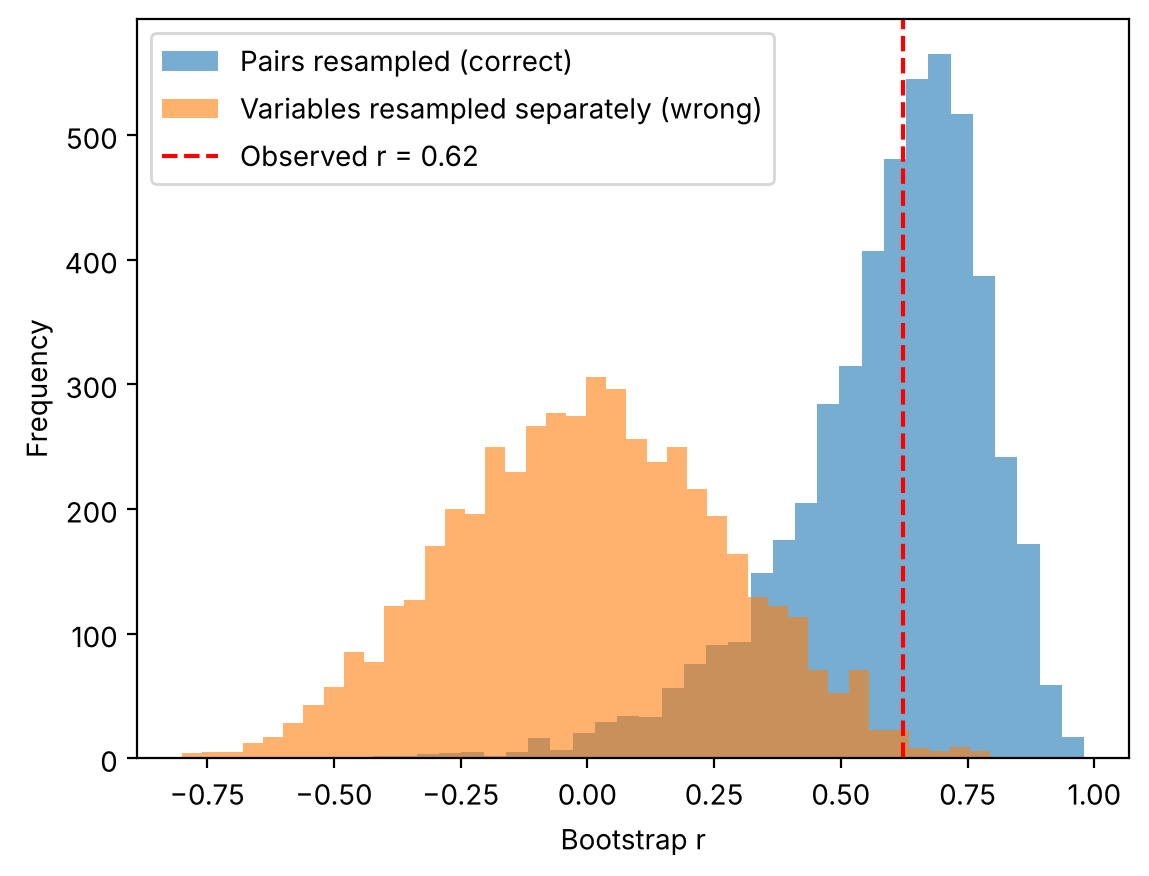

In [12]:
volume = np.array([3.19, 3.62, 3.76, 3.76, 4.04, 3.27, 3.59, 3.27, 2.90, 3.15, 3.45, 3.08, 3.33, 3.79, 3.60])
recall = np.array([20, 25, 24, 14, 36, 9, 24, 17, 13, 18, 19, 21, 11, 31, 13])
n = len(volume)
B = 5000
rng = np.random.default_rng(11)

r_obs = np.corrcoef(volume, recall)[0, 1]
print(f"Observed r = {r_obs:.3f}")

# Correct: resample PARTICIPANTS (pairs stay together)
boot_r = np.empty(B)
for b in range(B):
    idx = rng.integers(0, n, n)                      # indices drawn with replacement
    boot_r[b] = np.corrcoef(volume[idx], recall[idx])[0, 1]
lo, hi = np.percentile(boot_r, [2.5, 97.5])
print(f"Correct bootstrap 95% CI for r: [{lo:.2f}, {hi:.2f}]")

# Wrong: resample each variable independently (breaks the pairs)
wrong_r = np.empty(B)
for b in range(B):
    wrong_r[b] = np.corrcoef(rng.choice(volume, n), rng.choice(recall, n))[0, 1]
lo_w, hi_w = np.percentile(wrong_r, [2.5, 97.5])
print(f"Wrong bootstrap 95% CI for r:   [{lo_w:.2f}, {hi_w:.2f}]")

plt.hist(boot_r, bins=40, alpha=0.6, label="Pairs resampled (correct)")
plt.hist(wrong_r, bins=40, alpha=0.6, label="Variables resampled separately (wrong)")
plt.axvline(r_obs, color="red", linestyle="dashed", label=f"Observed r = {r_obs:.2f}")
plt.xlabel("Bootstrap r")
plt.ylabel("Frequency")
plt.legend()
plt.show()

- The resampling unit is the **participant**: each bootstrap sample draws 15 participants with replacement and keeps each participant's (volume, recall) pair together. The correct CI excludes 0, consistent with a positive association.
- Resampling the variables separately **destroys the pairing**, so the bootstrap distribution is centred near 0. That is a simulation of "no correlation", not of the sampling variability of the observed $r$. The bootstrap must mimic how the data were actually sampled (here: participants were sampled, not single numbers).

## Part 3: Bug Hunt

**3.8** Each snippet below contains one bug. First **predict** what the output will look like, then run the code, explain the bug, and fix it.

In [ ]:
rng = np.random.default_rng(0)
x = np.array([320, 340, 310, 300, 330, 290, 295, 280, 275, 285])

# Snippet A: bootstrap SE of the mean
means = [rng.choice(x, size=len(x), replace=False).mean() for _ in range(5000)]
print("A: bootstrap SE =", np.std(means, ddof=1))

# Snippet B: permutation test for a mean difference (first 5 vs last 5)
g1, g2 = x[:5], x[5:]
obs = g1.mean() - g2.mean()
pooled = np.concatenate([g1, g2])
diffs = []
for _ in range(5000):
    s = rng.choice(pooled, size=len(pooled), replace=True)
    diffs.append(s[:5].mean() - s[5:].mean())
print("B: p =", np.mean(np.abs(diffs) >= abs(obs)))

# Snippet C: bootstrap 95% CI of the mean
means_c = [rng.choice(x, size=len(x) // 2, replace=True).mean() for _ in range(5000)]
print("C: 95% CI =", np.percentile(means_c, [2.5, 97.5]))

# Your explanation and fixes:
# your answer

### Solution 3.8

In [14]:
rng = np.random.default_rng(0)
x = np.array([320, 340, 310, 300, 330, 290, 295, 280, 275, 285])

# A - Bug: replace=False just reorders the 10 values, so every "bootstrap" mean
#     equals the original mean and SE = 0. Fix: replace=True.
means = [rng.choice(x, size=len(x), replace=True).mean() for _ in range(5000)]
print(f"A (fixed): bootstrap SE = {np.std(means, ddof=1):.2f}  (analytic s/sqrt(n) = {x.std(ddof=1) / np.sqrt(len(x)):.2f})")

# B - Bug: replace=True turns the permutation test into a bootstrap. Some
#     observations appear twice, others vanish. Fix: shuffle WITHOUT replacement.
g1, g2 = x[:5], x[5:]
obs = g1.mean() - g2.mean()
pooled = np.concatenate([g1, g2])
diffs = []
for _ in range(5000):
    s = rng.permutation(pooled)
    diffs.append(s[:5].mean() - s[5:].mean())
print(f"B (fixed): p = {np.mean(np.abs(diffs) >= abs(obs)):.4f}")

# C - Bug: resamples of size n/2 have more variability than the real sample of
#     size n, so the CI is too wide. Fix: size=len(x).
means_c = [rng.choice(x, size=len(x), replace=True).mean() for _ in range(5000)]
print("C (fixed): 95% CI =", np.percentile(means_c, [2.5, 97.5]).round(1))

A (fixed): bootstrap SE = 6.49  (analytic s/sqrt(n) = 6.92)
B (fixed): p = 0.0056
C (fixed): 95% CI = [290.  315.5]


| Snippet | Symptom | Bug | Fix |
|---|---|---|---|
| A | SE = 0 (or ~1e-13) | Bootstrap without replacement only reorders the sample | `replace=True` |
| B | p-value slightly off, because the null distribution has the wrong spread | "Permutation" with replacement: observations are duplicated or lost | `rng.permutation` (without replacement) |
| C | CI too wide (by about a factor $\sqrt{2}$) | Resample size ≠ original sample size | `size=len(x)` |

## Part 4: Permutation Test vs. Bootstrap on the Same Data

**3.9** The lecture analysed $A = \{5, 7, 6\}$ and $B = \{8, 9, 10\}$ with both methods.

1. Run an **exact** permutation test (two-sided) on the mean difference.
2. Compute a bootstrap 95 % percentile CI for the mean difference ($B = 10{,}000$, resampling each group separately, `rng = np.random.default_rng(12)`).
3. The two methods seem to disagree: one says "not significant", the other "CI excludes 0". Explain why, and say which conclusion you trust more here.

In [ ]:
A = np.array([5, 7, 6])
B_grp = np.array([8, 9, 10])

# your answer

### Solution 3.9

In [16]:
A = np.array([5, 7, 6])
B_grp = np.array([8, 9, 10])

# 1. Exact permutation test (reuse the function from 3.2)
obs, p_exact, _ = exact_perm_test(A, B_grp)
print(f"Observed difference = {obs:.2f}, exact permutation p = {p_exact:.3f}")

# 2. Bootstrap percentile CI
rng = np.random.default_rng(12)
boot = np.array([rng.choice(A, 3).mean() - rng.choice(B_grp, 3).mean() for _ in range(10000)])
print(f"Bootstrap 95% CI = [{np.percentile(boot, 2.5):.2f}, {np.percentile(boot, 97.5):.2f}]")
print(f"Number of distinct bootstrap values: {len(np.unique(boot.round(6)))}")

Observed difference = -3.00, exact permutation p = 0.100


Bootstrap 95% CI = [-4.33, -1.67]
Number of distinct bootstrap values: 13


**Why they disagree:**

- They answer **different questions**. The permutation test builds the distribution of the statistic **under $H_0$** (labels exchangeable) and returns a p-value. With 3 + 3 observations, the smallest possible two-sided p is 0.10 (see **3.1**), so it can never reach significance.
- The bootstrap estimates the **sampling variability** of the observed difference, assuming the sample **represents the population**. With only 3 values per group this assumption is weak: the bootstrap can only recombine 3 values per group, so it **underestimates** the true variability and the percentile CI is too narrow (here it excludes 0).

**Which to trust:** with such tiny samples, the **exact permutation test** is more trustworthy. Its validity only requires exchangeability under $H_0$, and its p-value is exact. The bootstrap is an approximation that needs reasonably large samples. Report: "the data are compatible with a difference, but a 3 + 3 design cannot provide significant evidence; a larger sample is needed."

## Conceptual Questions

1. In **3.2** you could enumerate all 924 splits. Why not always do that? When is Monte Carlo sampling necessary?
2. A permutation test assumes exchangeability under $H_0$. Give an example of a two-group comparison where this assumption is doubtful even though the data are not normal.
3. In **3.6** the bootstrap CI excludes 0 and the permutation test is significant. Do the two methods always agree for moderate sample sizes? What is the main *additional* information the bootstrap provides?
4. Why is the bootstrap described as useful "when analytical formulas are hard to derive"? Give a brain-science example of a statistic for which you would use it.
5. Could you use the bootstrap distribution from **3.6** to compute a p-value directly, as in a permutation test? Why is that not straightforward?

### Answers

1. The number of splits grows explosively: $\binom{20}{10} = 184{,}756$, $\binom{40}{20} \approx 1.4 \times 10^{11}$. Exact enumeration is feasible only for small samples. For larger samples, a random subset of permutations (e.g. 10,000) approximates the exact p-value with a small, controllable Monte Carlo error.

2. If the groups differ in **variance or shape** even when the means are equal (e.g. patients have much more variable reaction times than controls), the labels are not exchangeable under "equal means". A permutation test of the mean difference can then reject because of the variance difference. Another example: **dependent** observations, such as repeated trials of the same participant spread across both groups.

3. With moderate samples they usually agree, but not always (borderline cases can differ, because they use different distributions and assumptions). The bootstrap's main extra is the **interval estimate**: a standard error and a CI that show the plausible size and precision of the effect, not only whether it is different from zero.

4. For the mean, $SE = s/\sqrt{n}$ is known, but for many statistics no simple formula exists: the median, a correlation in non-normal data, a ratio of two means, a peak latency in an ERP, a graph-theory measure of connectivity (e.g. clustering coefficient), or the cross-validated accuracy of a classifier. The bootstrap simply recomputes the statistic on each resample.

5. Not directly. The bootstrap distribution is centred on the **observed** effect, not on the null hypothesis, so the fraction of bootstrap values "more extreme than observed" is not a p-value. A bootstrap test needs extra steps (for example shifting the groups to a common mean so that $H_0$ is true, or inverting the CI). The permutation test is built for p-values. The bootstrap is mainly built for SEs and CIs.